# 08d mcap with exocentric camera
Writes the version 1.1 mcap files, the three body cameras plus the fixed exocentric camera, from the existing episode files.

## Setup
Loads the libraries and sets the two flags.

In [1]:
import json, hashlib, time, datetime, zipfile, shutil, subprocess, heapq, os, sys, re
from importlib import metadata
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import av
import mcap
import google.protobuf
from mcap.reader import make_reader
from mcap.writer import CompressionType
from mcap_protobuf.writer import Writer
from foxglove_schemas_protobuf.CompressedVideo_pb2 import CompressedVideo

FORCE = False
FINAL_KEYS_ONLY = False

NB_NAME = "08d_mcap_with_exo.ipynb"
CAMS = ["cam_high", "cam_left_wrist", "cam_right_wrist", "cam_ext"]
BODY = {"head": "cam_high", "left": "cam_left_wrist", "right": "cam_right_wrist"}
T_START = time.time()

# results shared between the cells
EP_IDS, E, META, REQ = [], {}, {}, {}
R, LT, NEAR, SHA = {}, {}, {}, {}
CHK, EPCHK, TC, TC6, MAN = None, {}, {}, None, None
ZERO_UTC_US = LAG06 = LAG08B = UNC = METHOD = ROOT_SHA = ROOT_START = None
LAG_DIFF = None

c:\workstation\3RD YEAR\ego_pipeline\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
def problem(step, ex):
    print(f"problem in {step}: {type(ex).__name__}: {ex}")


def ver(name):
    try:
        return metadata.version(name)
    except Exception:
        return "unknown"


def read_json(p):
    with open(p, "r", encoding="utf-8") as f:
        return json.load(f)


def sha_file(p, block=8 * 1024 * 1024):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        while True:
            b = f.read(block)
            if not b:
                break
            h.update(b)
    return h.hexdigest()


def pick_key(z, names):
    keys = list(z.files)
    low = {k.lower(): k for k in keys}
    for n in names:
        if n in low:
            return low[n]
    for n in names:
        for k in keys:
            if n in k.lower():
                return k
    return None


def find_val(d, key):
    if isinstance(d, dict):
        if key in d:
            return d[key]
        for v in d.values():
            r = find_val(v, key)
            if r is not None:
                return r
    return None


EPOCH = datetime.datetime(1970, 1, 1, tzinfo=datetime.timezone.utc)


def iso_to_ns(s):
    m = re.match(r"^(.*?)(\.\d+)?(Z|[+-]\d\d:?\d\d)?$", s.strip())
    base, frac, tz = m.group(1), m.group(2), m.group(3)
    if tz is None or tz == "Z":
        tz = "+00:00"
    if re.match(r"^[+-]\d{4}$", tz):
        tz = tz[:3] + ":" + tz[3:]
    dt = datetime.datetime.fromisoformat(base + tz)
    sec = (dt - EPOCH) // datetime.timedelta(seconds=1)
    ns = int((frac or ".0")[1:].ljust(9, "0")[:9])
    return sec * 10**9 + ns


def nal_types(b):
    out = set()
    i = b.find(b"\x00\x00\x01")
    while i != -1 and i + 3 < len(b):
        out.add(b[i + 3] & 31)
        i = b.find(b"\x00\x00\x01", i + 3)
    return out

In [3]:
VERS = {
    "python": sys.version.split()[0],
    "mcap": ver("mcap"),
    "mcap_protobuf": ver("mcap-protobuf-support"),
    "foxglove_schemas_protobuf": ver("foxglove-schemas-protobuf"),
    "protobuf": google.protobuf.__version__,
    "numpy": np.__version__,
}
print("mcap", VERS["mcap"], "| mcap_protobuf", VERS["mcap_protobuf"],
      "| foxglove_schemas_protobuf", VERS["foxglove_schemas_protobuf"], "| protobuf", VERS["protobuf"])

ROOT = Path.cwd().resolve().parent
if not (ROOT / "configs" / "config.yaml").exists():
    raise RuntimeError(f"configs\\config.yaml not found under {ROOT}; start this notebook from the notebooks folder of the project")
with open(ROOT / "configs" / "config.yaml", "r", encoding="utf-8") as f:
    cfg = yaml.safe_load(f)
REPORTS, EPS, OUT = ROOT / "reports", ROOT / "episodes", ROOT / "mcap" / "v1_1"
REPORTS.mkdir(exist_ok=True)
OUT.mkdir(parents=True, exist_ok=True)
print("project root:", ROOT)
print("config keys:", list(cfg)[:10] if isinstance(cfg, dict) else type(cfg).__name__)

try:
    s06 = read_json(REPORTS / "06_summary.json")
    a06 = read_json(REPORTS / "06_anchor_estimate.json")
    s05 = read_json(REPORTS / "05_summary.json")
    b08 = read_json(REPORTS / "08b_exo_sync.json")
    t04 = read_json(REPORTS / "04_time_anchor.json")
    man = pd.read_csv(REPORTS / "raw_manifest.csv")
    EP_IDS = [str(x) for x in find_val(s06, "episode_ids")]
    ZERO_UTC_US = int(find_val(a06, "session_zero_utc_us"))
    LAG06 = float(find_val(a06, "lag_s"))
    LAG08B = float(find_val(b08, "lag_s"))
    UNC = find_val(b08, "uncertainty_s")
    METHOD = find_val(b08, "method")
    ROOT_START = find_val(t04, "root_start_utc")
    sha_col = [c for c in man.columns if "sha" in c.lower()][0]
    rv = man[man["kind"] == "root_video"]
    ROOT_SHA = str(rv.iloc[0][sha_col])
    print("episodes:", EP_IDS)
    print("session_zero_utc_us (06):", ZERO_UTC_US, "| session_zero_us (05):", find_val(s05, "session_zero_us"))
    print("root_start_utc:", ROOT_START, "| root video sha256:", ROOT_SHA[:16] + "...", f"({len(rv)} row)")
except Exception as ex:
    problem("loading reports", ex)

try:
    LAG_DIFF = abs(LAG06 - LAG08B)
    print(f"lag_s notebook 06: {LAG06:.4f} | notebook 08b: {LAG08B:.4f} | difference: {LAG_DIFF:.4f} s")
    if LAG_DIFF > 0.05:
        print("WARNING: the lag of notebook 06 differs from the refined lag of notebook 08b by more than 0.05 s.")
        print("WARNING: notebook 06 must be re-run with the refined lag. Continuing anyway.")
except Exception as ex:
    problem("lag comparison", ex)

mcap 1.5.0 | mcap_protobuf 0.5.4 | foxglove_schemas_protobuf 0.4.0 | protobuf 7.36.2
project root: C:\workstation\3RD YEAR\ego_pipeline
config keys: ['source_root', 'directories', 'devices', 'nominal_fps', 'chunk_seconds_hypothesis', 'thresholds', 'time', 'identity']
episodes: ['vendorX_2026-10-11_op01_000001', 'vendorX_2026-10-11_op01_000002', 'vendorX_2026-10-11_op01_000003', 'vendorX_2026-10-11_op01_000004']
session_zero_utc_us (06): 1791729630470744 | session_zero_us (05): 7782913
root_start_utc: 2026-10-11T14:38:44.654044+00:00 | root video sha256: ae387c43cf8983b8... (1 row)
lag_s notebook 06: 105.8167 | notebook 08b: 105.8167 | difference: 0.0000 s


In [4]:
def load_au(npz_path, h264_path, show=False):
    z = np.load(npz_path)
    if show:
        print(npz_path.name, "keys:", z.files)
    ko = pick_key(z, ["offsets", "offset", "au_offsets", "off"])
    ks = pick_key(z, ["sizes", "size", "au_sizes", "len"])
    kk = pick_key(z, ["keyframe", "is_keyframe", "is_key", "key", "idr"])
    kf = pick_key(z, ["frame_index", "frame_idx", "frame_indices", "index", "idx"])
    off = np.asarray(z[ko]).astype(np.int64)
    fsize = h264_path.stat().st_size
    if ks is not None:
        size = np.asarray(z[ks]).astype(np.int64)
        off = off[:len(size)]
    else:
        b = off if off[-1] == fsize else np.append(off, fsize)
        size = np.diff(b)
        off = b[:-1]
    key = np.asarray(z[kk]).astype(bool) if kk is not None else None
    fidx = np.asarray(z[kf]).astype(np.int64) if (kf is not None and kf != kk and len(z[kf]) == len(size)) else np.arange(len(size))
    return {"off": off, "size": size, "key": key, "fidx": fidx}


count_rows = []
for n_ep, eid in enumerate(EP_IDS):
    try:
        d = EPS / eid
        v = d / "video"
        first = n_ep == 0
        e = {"dir": d, "cams": {}}
        for dev, cam in BODY.items():
            fz = np.load(d / f"frames_{dev}.npz")
            if first and dev == "head":
                print("frames npz keys:", fz.files)
            k = pick_key(fz, ["ts_session_us", "ts_session", "ts_us"])
            rel = np.asarray(fz[k]).astype(np.float64)
            au = load_au(v / f"{cam}_au.npz", v / f"{cam}.h264", show=first and dev == "head")
            e["cams"][cam] = {"h264": v / f"{cam}.h264", "au": au, "ts_rel_us": rel, "n_frames": len(rel)}
        zt = np.load(v / "cam_ext_timestamps.npz")
        if first:
            print("cam_ext_timestamps npz keys:", zt.files)
        k_ns = pick_key(zt, ["ts_utc_ns"])
        k_pts = pick_key(zt, ["pts_s", "pts"])
        k_root = pick_key(zt, ["root_frame_idx", "root_frame_index", "root_frame", "root"])
        ts_ext = np.asarray(zt[k_ns]).astype(np.int64)
        au = load_au(v / "cam_ext_au.npz", v / "cam_ext.h264", show=first)
        e["cams"]["cam_ext"] = {
            "h264": v / "cam_ext.h264", "au": au, "ts_ns": ts_ext, "n_frames": len(ts_ext),
            "pts_s": np.asarray(zt[k_pts]).astype(np.float64) if k_pts else None,
            "root_idx": np.asarray(zt[k_root]).astype(np.int64) if k_root else None,
        }
        E[eid] = e
        row = {"episode": eid}
        for c in CAMS:
            row[c] = f"{e['cams'][c]['n_frames']} / {len(e['cams'][c]['au']['size'])}"
        count_rows.append(row)
    except Exception as ex:
        problem(f"loading episode {eid}", ex)

print("frames / access units per camera:")
print(pd.DataFrame(count_rows).to_string(index=False))

need = []
for eid in EP_IDS:
    d = EPS / eid
    v = d / "video"
    need += [d / f"frames_{x}.npz" for x in BODY]
    need += [d / "episode_metadata_draft.json", d / "episode_metadata_mcap_strings.json"]
    need += [v / "video_manifest.json", v / "video_manifest_exo.json", v / "cam_ext_timestamps.npz"]
    for c in CAMS:
        need += [v / f"{c}.h264", v / f"{c}_au.npz"]
missing = [p for p in need if not p.exists()]
print(f"input files checked: {len(need)}, missing: {len(missing)}")
for p in missing[:20]:
    print("  missing:", p.relative_to(ROOT))

frames npz keys: ['ts_session_us', 'flags', 'source_clip', 'local_i', 'global_n', 'acc', 'gyro', 'source_clips']
cam_high_au.npz keys: ['offsets', 'sizes', 'is_key', 'n_sps', 'n_pps', 'n_vcl', 'frame_index', 'first_is_aud']
cam_ext_timestamps npz keys: ['pts_s', 'ts_utc_ns', 'flag', 'root_frame_idx']
cam_ext_au.npz keys: ['offsets', 'sizes', 'is_key', 'frame_idx']
frames / access units per camera:
                       episode      cam_high cam_left_wrist cam_right_wrist       cam_ext
vendorX_2026-10-11_op01_000001 21240 / 21240  21239 / 21239   21239 / 21239 21269 / 21269
vendorX_2026-10-11_op01_000002   9390 / 9390    9390 / 9390     9390 / 9390   9403 / 9403
vendorX_2026-10-11_op01_000003 10410 / 10410  10410 / 10410   10409 / 10409 10423 / 10423
vendorX_2026-10-11_op01_000004 18000 / 18000  17999 / 17999   17999 / 17999 18024 / 18024
input files checked: 64, missing: 0


## Timestamps
Builds the utc time in nanoseconds for every frame of the four cameras and checks the mapping against the capture times.

In [5]:
R["ts"] = {}
rows2 = []
for eid in EP_IDS:
    try:
        e = E[eid]
        draft = read_json(e["dir"] / "episode_metadata_draft.json")
        e["start_ns"] = iso_to_ns(find_val(draft, "capture_start_iso"))
        e["stop_ns"] = iso_to_ns(find_val(draft, "capture_stop_iso"))
        for cam in BODY.values():
            c = e["cams"][cam]
            c["ts_ns"] = (ZERO_UTC_US + np.rint(c["ts_rel_us"]).astype(np.int64)) * 1000
        hi, ex = e["cams"]["cam_high"]["ts_ns"], e["cams"]["cam_ext"]["ts_ns"]
        r = {
            "head_start_ms": (hi[0] - e["start_ns"]) / 1e6,
            "ext_start_ms": (ex[0] - e["start_ns"]) / 1e6,
            "ext_stop_ms": (e["stop_ns"] - ex[-1]) / 1e6,
        }
        R["ts"][eid] = r
        for cam in CAMS:
            c = e["cams"][cam]
            t = c["ts_ns"]
            d = np.diff(t)
            rows2.append({"episode": eid, "camera": cam, "n_ts": len(t), "n_au": len(c["au"]["size"]),
                          "length_ok": len(t) == len(c["au"]["size"]),
                          "decreases": int((d < 0).sum()), "equal": int((d == 0).sum())})
        flag = "" if abs(r["head_start_ms"]) <= 1 else "  <- more than 1 ms"
        print(f"{eid}: first head frame minus capture start {r['head_start_ms']:.3f} ms{flag}")
        print(f"{eid}: cam_ext first minus start {r['ext_start_ms']:.1f} ms, stop minus last {r['ext_stop_ms']:.1f} ms")
    except Exception as ex:
        problem(f"timestamps {eid}", ex)

print(pd.DataFrame(rows2).to_string(index=False))

vendorX_2026-10-11_op01_000001: first head frame minus capture start -0.038 ms
vendorX_2026-10-11_op01_000001: cam_ext first minus start 28.7 ms, stop minus last 14.3 ms
vendorX_2026-10-11_op01_000002: first head frame minus capture start -0.257 ms
vendorX_2026-10-11_op01_000002: cam_ext first minus start 8.8 ms, stop minus last 8.4 ms
vendorX_2026-10-11_op01_000003: first head frame minus capture start 0.474 ms
vendorX_2026-10-11_op01_000003: cam_ext first minus start 32.1 ms, stop minus last 12.4 ms
vendorX_2026-10-11_op01_000004: first head frame minus capture start 0.410 ms
vendorX_2026-10-11_op01_000004: cam_ext first minus start 15.7 ms, stop minus last 29.8 ms
                       episode          camera  n_ts  n_au  length_ok  decreases  equal
vendorX_2026-10-11_op01_000001        cam_high 21240 21240       True          0      0
vendorX_2026-10-11_op01_000001  cam_left_wrist 21239 21239       True          0      0
vendorX_2026-10-11_op01_000001 cam_right_wrist 21239 21239  

In [6]:
# utc of cam_ext against the root video clock, should be a constant offset
try:
    e = E[EP_IDS[0]]["cams"]["cam_ext"]
    root_ns = iso_to_ns(ROOT_START)
    off = e["ts_ns"] - (root_ns + np.rint(e["pts_s"] * 1e9).astype(np.int64))
    print(f"cam_ext utc minus (root start + pts): mean {off.mean() / 1e9:.4f} s, spread {(off.max() - off.min()) / 1e6:.2f} ms")
except Exception as ex:
    problem("root clock check", ex)

cam_ext utc minus (root start + pts): mean 0.0000 s, spread 0.00 ms


## Metadata
Builds the final metadata dictionary of each episode from the version 1 strings, all values as strings.

In [7]:
PLAN = None


def ext_timing(eid):
    # mean_fps, share_lt25ms and share_gt40ms of cam_ext for this episode, read from reports\08c_frame_plan.csv
    global PLAN
    if PLAN is None:
        PLAN = pd.read_csv(REPORTS / "08c_frame_plan.csv", dtype=str)
    p = PLAN
    if "camera" in p.columns:
        p = p[p["camera"].str.strip() == "cam_ext"]
    col = [c for c in p.columns if "episode" in c.lower()][0]
    row = p[p[col].str.strip() == str(eid)]
    if len(row) != 1:
        raise RuntimeError(f"expected one row for episode {eid} in 08c_frame_plan.csv, found {len(row)}")
    row = row.iloc[0]
    return float(row["mean_fps"]), float(row["share_lt25ms"]), float(row["share_gt40ms"])


def pct(x):
    return f"{x * 100:.3g} %"


def timing_text(fps, lt25, gt40):
    if lt25 == 0 and gt40 == 0:
        limits = "no interval shorter than 25 ms or longer than 40 ms"
    else:
        a = "no interval shorter than 25 ms" if lt25 == 0 else f"{pct(lt25)} of the intervals shorter than 25 ms"
        b = "no interval longer than 40 ms" if gt40 == 0 else f"{pct(gt40)} of the intervals longer than 40 ms"
        limits = f"{a} and {b}"
    return f"near-constant frame rate of about {fps:.3f} fps, true timestamp per message, {limits}"


def rig_add(fps):
    return ("and one fixed exocentric phone camera (portrait 1080x1920, "
            f"near-constant frame rate of about {fps:.3f} fps, audio removed)")


DROP = ["fps_rational", "pending", "assembly_stage"]
FIXED = ["episode_id", "capture_start_iso", "capture_stop_iso", "fps", "duration_sec", "max_timesteps"]


def new_producer(old):
    add = {"notebook": NB_NAME, "versions": VERS}
    if isinstance(old, dict):
        out = dict(old)
        out.update(add)
        return out
    if isinstance(old, str):
        try:
            obj = json.loads(old)
            if isinstance(obj, dict):
                obj.update(add)
                return obj
        except Exception:
            pass
        out = dict(add)
        out["previous"] = old
        return out
    return add


def build_meta(eid):
    e = E[eid]
    src = read_json(e["dir"] / "episode_metadata_mcap_strings.json")
    meta = {str(k): v if isinstance(v, str) else json.dumps(v) for k, v in src.items()}
    orig = dict(meta)
    REQ[eid] = set(orig) - (set(DROP) if FINAL_KEYS_ONLY else set())

    for k in ["language_instruction", "spans", "pose_modality", "coverage"]:
        meta[k] = "null"

    fps, lt25, gt40 = ext_timing(eid)
    cam_ext_info = {"role": "exocentric", "resolution": [1080, 1920], "fps": round(fps, 3),
                    "is_pose_source": False, "timing": timing_text(fps, lt25, gt40)}
    cams = json.loads(meta["cameras"])
    if isinstance(cams, list):
        cams.append(dict(cam_ext_info, name="cam_ext"))
    else:
        cams["cam_ext"] = cam_ext_info
    meta["cameras"] = json.dumps(cams, ensure_ascii=False)

    rig = [k for k in meta if k.lower().startswith("rig") or "_rig" in k.lower()]
    rig = sorted(rig, key=lambda k: "description" not in k.lower())
    if rig:
        if "exocentric" not in meta[rig[0]]:
            meta[rig[0]] = meta[rig[0]].rstrip().rstrip(".") + " " + rig_add(fps)
    else:
        print(f"problem in metadata {eid}: no rig description key found")

    prov = json.loads(meta["source_provenance"])
    ext = e["cams"]["cam_ext"]
    frame_range = [int(ext["root_idx"][0]), int(ext["root_idx"][-1])] if ext["root_idx"] is not None else None
    interval = [float(ext["pts_s"][0]), float(ext["pts_s"][-1])] if ext["pts_s"] is not None else None
    prov["exo"] = {
        "source_file": "video_20261011_200844.mp4",
        "sha256": ROOT_SHA,
        "source_frame_range": frame_range,
        "root_time_interval_s": interval,
        "lag_s": LAG08B,
        "lag_uncertainty_s": UNC,
        "sync_method": METHOD,
        "privacy_note": "cam_ext shows the subject's face; audio removed",
    }
    if "producer" in prov or "producer" not in meta:
        prov["producer"] = new_producer(prov.get("producer"))
    else:
        p = new_producer(meta["producer"])
        meta["producer"] = p if isinstance(p, str) else json.dumps(p, ensure_ascii=False)

    meta["assembly_stage"] = "v1_1_video_only"
    if FINAL_KEYS_ONLY:
        moved = {}
        for k in DROP:
            if k in meta:
                v = meta.pop(k)
                if k == "pending":
                    try:
                        v = json.loads(v)
                    except Exception:
                        pass
                moved[k] = v
        prov["final_keys_moved"] = moved
    meta["source_provenance"] = json.dumps(prov, ensure_ascii=False)

    for k in FIXED:
        if k in orig and meta.get(k) != orig[k]:
            print(f"problem in metadata {eid}: {k} changed")
    if not all(isinstance(k, str) and isinstance(v, str) for k, v in meta.items()):
        print(f"problem in metadata {eid}: non-string value")
    return meta


for eid in EP_IDS:
    try:
        META[eid] = build_meta(eid)
    except Exception as ex:
        problem(f"metadata {eid}", ex)

if EP_IDS and EP_IDS[0] in META:
    print(f"metadata of {EP_IDS[0]}:")
    print(json.dumps(META[EP_IDS[0]], indent=2, ensure_ascii=False))

metadata of vendorX_2026-10-11_op01_000001:
{
  "episode_id": "vendorX_2026-10-11_op01_000001",
  "capture_start_iso": "2026-10-11T14:45:02.494Z",
  "capture_stop_iso": "2026-10-11T14:56:50.506Z",
  "fps": "30.0",
  "fps_rational": "30/1",
  "duration_sec": "708.0",
  "max_timesteps": "21240",
  "rig": "{\"description\": \"chest-mounted egocentric camera looking down (raw image rotated 180 degrees) + left and right wrist cameras looking at the palms, 1920x1080 at 30 fps, IMU on every device\"} and one fixed exocentric phone camera (portrait 1080x1920, near-constant frame rate of about 30.041 fps, audio removed)",
  "cameras": "{\"cam_high\": {\"role\": \"egocentric\", \"resolution\": [1920, 1080], \"is_pose_source\": true}, \"cam_left_wrist\": {\"role\": \"left_wrist\", \"resolution\": [1920, 1080]}, \"cam_right_wrist\": {\"role\": \"right_wrist\", \"resolution\": [1920, 1080]}, \"cam_ext\": {\"role\": \"exocentric\", \"resolution\": [1080, 1920], \"fps\": 30.041, \"is_pose_source\": f

## Write mcap files
Writes one mcap file per episode into mcap\v1_1 with the four camera channels, merged in log time order.

In [8]:
def get_inner(w):
    for name in ("_Writer__writer", "_writer", "writer"):
        x = getattr(w, name, None)
        if x is not None and hasattr(x, "add_metadata"):
            return x
    for v in vars(w).values():
        if hasattr(v, "add_metadata"):
            return v
    raise RuntimeError("cannot reach add_metadata of the mcap_protobuf writer")


def write_episode(eid):
    e = E[eid]
    out = OUT / f"{eid}.mcap"
    part = OUT / f"{eid}.mcap.part"
    side = OUT / f"{eid}.mcap.sha256"
    assert out.parent.name == "v1_1"
    if out.exists() and side.exists() and not FORCE:
        rec = side.read_text().split()
        if len(rec) == 2 and int(rec[1]) == out.stat().st_size:
            SHA[eid] = rec[0]
            print(f"{eid}: file exists with recorded sha256, skipped")
            return
    t0 = time.time()
    total = sum(len(e["cams"][c]["ts_ns"]) for c in CAMS)
    handles = {c: open(e["cams"][c]["h264"], "rb") for c in CAMS}

    def stream(c, prio):
        ts = e["cams"][c]["ts_ns"]
        for i in range(len(ts)):
            yield (int(ts[i]), prio, i, c)

    try:
        with open(part, "wb") as f:
            w = Writer(f, compression=CompressionType.NONE)
            get_inner(w).add_metadata("episode_metadata", META[eid])
            bar = tqdm(total=total, desc=eid, unit="msg")
            n = 0
            for ts, prio, i, c in heapq.merge(*[stream(c, p) for p, c in enumerate(CAMS)]):
                au = e["cams"][c]["au"]
                h = handles[c]
                h.seek(int(au["off"][i]))
                msg = CompressedVideo()
                msg.timestamp.seconds = ts // 10**9
                msg.timestamp.nanos = ts % 10**9
                msg.frame_id = c
                msg.format = "h264"
                msg.data = h.read(int(au["size"][i]))
                w.write_message(topic=f"/cameras/{c}", message=msg, log_time=ts, publish_time=ts,
                                sequence=int(au["fidx"][i]))
                n += 1
                if n % 500 == 0:
                    bar.update(500)
            bar.update(n % 500)
            bar.close()
            w.finish()
        os.replace(part, out)
    except Exception:
        if part.exists():
            part.unlink()
        raise
    finally:
        for h in handles.values():
            h.close()
    SHA[eid] = sha_file(out)
    side.write_text(f"{SHA[eid]} {out.stat().st_size}\n")
    print(f"{eid}: {n} messages, {out.stat().st_size / 1e6:.1f} MB, {time.time() - t0:.1f} s")


for eid in EP_IDS:
    try:
        if eid not in META or eid not in E:
            print(f"{eid}: skipped, metadata or inputs missing")
            continue
        write_episode(eid)
    except Exception as ex:
        problem(f"writing {eid}", ex)

vendorX_2026-10-11_op01_000001: file exists with recorded sha256, skipped
vendorX_2026-10-11_op01_000002: file exists with recorded sha256, skipped
vendorX_2026-10-11_op01_000003: file exists with recorded sha256, skipped
vendorX_2026-10-11_op01_000004: file exists with recorded sha256, skipped


## Read back
Reads every file again and checks channels, counts, order, the first access unit and the reassembled h264 bytes.

In [9]:
def decode_size(data):
    try:
        ctx = av.CodecContext.create("h264", "r")
        frames = ctx.decode(av.Packet(data))
        if not frames:
            frames = ctx.decode(None)
        if frames:
            return f"{frames[0].width}x{frames[0].height}"
        return "none"
    except Exception:
        return "error"


rows5 = []
for eid in EP_IDS:
    p = OUT / f"{eid}.mcap"
    ep = {"opens": False}
    EPCHK[eid] = ep
    LT[eid] = {}
    try:
        with open(p, "rb") as f:
            rd = make_reader(f)
            summ = rd.get_summary()
            st = summ.statistics
            info = {}
            for cid, ch in summ.channels.items():
                sc = summ.schemas.get(ch.schema_id)
                n_stat = st.channel_message_counts.get(cid) if st is not None else None
                info[ch.topic] = (sc.name if sc else "", ch.message_encoding, n_stat)
            ep["opens"] = True
            ep["n_channels"] = len(info)
            ep["schema_ok"] = all(v[0] == "foxglove.CompressedVideo" and v[1] == "protobuf" for v in info.values())
            ep["stats_total"] = st.message_count if st is not None else None

            metas = [m for m in rd.iter_metadata() if m.name == "episode_metadata"]
            ep["meta_found"] = len(metas) == 1
            if metas:
                md = metas[0].metadata
                ep["meta_n"] = len(md)
                ep["meta_ok"] = all(isinstance(k, str) and isinstance(v, str) for k, v in md.items()) and set(md) == set(META[eid])

            prev, order_all = -1, True
            lt, hs, firsts = {}, {}, {}
            for schema, ch, m in rd.iter_messages(log_time_order=False):
                cam = ch.topic.split("/")[-1]
                if m.log_time < prev:
                    order_all = False
                prev = m.log_time
                lt.setdefault(cam, []).append(m.log_time)
                cv = CompressedVideo()
                cv.ParseFromString(m.data)
                if cam not in firsts:
                    firsts[cam] = cv
                hs.setdefault(cam, hashlib.sha256()).update(cv.data)
            ep["order_global_ok"] = order_all

        for cam in CAMS:
            topic = f"/cameras/{cam}"
            arr = np.array(lt.get(cam, []), dtype=np.int64)
            LT[eid][cam] = arr
            cv = firsts.get(cam)
            nals = sorted(nal_types(cv.data)) if cv is not None else []
            sha_stream = hs[cam].hexdigest() if cam in hs else ""
            sha_h264 = sha_file(E[eid]["cams"][cam]["h264"])
            expected = len(E[eid]["cams"][cam]["ts_ns"])
            sc_name, enc, n_stat = info.get(topic, ("", "", None))
            rows5.append({
                "episode_id": eid, "camera": cam, "topic": topic, "schema": sc_name, "encoding": enc,
                "messages": len(arr), "stats_messages": n_stat, "expected_frames": expected,
                "count_ok": len(arr) == expected and n_stat == expected,
                "order_channel_ok": bool((np.diff(arr) >= 0).all()) if len(arr) else False,
                "format_ok": cv is not None and cv.format == "h264",
                "frame_id_ok": cv is not None and cv.frame_id == cam,
                "first_nal_types": " ".join(str(x) for x in nals),
                "idr_sps_pps_ok": {5, 7, 8}.issubset(nals),
                "decoded_size": decode_size(cv.data) if cv is not None else "",
                "sha256_mcap_stream": sha_stream, "sha256_h264_file": sha_h264,
                "identical": sha_stream == sha_h264 and sha_stream != "",
            })
        ep_rows = [r for r in rows5 if r["episode_id"] == eid]
        print(f"{eid}: channels {ep['n_channels']}, counts " + "/".join(str(r["messages"]) for r in ep_rows) +
              f", metadata keys {ep.get('meta_n')}, order ok {ep['order_global_ok']}")
    except Exception as ex:
        problem(f"read back {eid}", ex)

CHK = pd.DataFrame(rows5)
if len(CHK):
    CHK.to_csv(REPORTS / "08d_mcap_check.csv", index=False)
    show = ["episode_id", "camera", "messages", "expected_frames", "order_channel_ok", "first_nal_types", "decoded_size", "identical"]
    print(CHK[show].to_string(index=False))

vendorX_2026-10-11_op01_000001: channels 4, counts 21240/21239/21239/21269, metadata keys 20, order ok True
vendorX_2026-10-11_op01_000002: channels 4, counts 9390/9390/9390/9403, metadata keys 20, order ok True
vendorX_2026-10-11_op01_000003: channels 4, counts 10410/10410/10409/10423, metadata keys 20, order ok True
vendorX_2026-10-11_op01_000004: channels 4, counts 18000/17999/17999/18024, metadata keys 20, order ok True
                    episode_id          camera  messages  expected_frames  order_channel_ok first_nal_types decoded_size  identical
vendorX_2026-10-11_op01_000001        cam_high     21240            21240              True       5 6 7 8 9    1920x1080       True
vendorX_2026-10-11_op01_000001  cam_left_wrist     21239            21239              True       5 6 7 8 9    1920x1080       True
vendorX_2026-10-11_op01_000001 cam_right_wrist     21239            21239              True       5 6 7 8 9    1920x1080       True
vendorX_2026-10-11_op01_000001         cam_e

## Time consistency
Compares the first and last message times with the capture times and the four cameras with each other.

In [10]:
PERIOD = 1e9 / 30
rows6 = []
for eid in EP_IDS:
    try:
        lt = LT[eid]
        hi, ex = lt["cam_high"], lt["cam_ext"]
        start, stop = E[eid]["start_ns"], E[eid]["stop_ns"]
        sd, ed = (hi[0] - start) / 1e6, (stop - hi[-1]) / 1e6
        j = np.searchsorted(ex, hi)
        a, b = np.clip(j - 1, 0, len(ex) - 1), np.clip(j, 0, len(ex) - 1)
        near = np.where(np.abs(ex[a] - hi) <= np.abs(ex[b] - hi), ex[a], ex[b])
        sdiff = (near - hi) / 1e6
        NEAR[eid] = (hi, sdiff)
        ad = np.abs(sdiff)
        TC[eid] = {"start_diff_ms": sd, "stop_diff_ms": ed, "near_mean_ms": float(ad.mean()),
                   "near_p95_ms": float(np.percentile(ad, 95)), "near_max_ms": float(ad.max())}
        for cam in CAMS:
            t = lt[cam]
            d = np.diff(t)
            big = d[d >= 50e6]
            rows6.append({
                "episode_id": eid, "camera": cam,
                "first_vs_high_ms": (t[0] - hi[0]) / 1e6, "last_vs_high_ms": (t[-1] - hi[-1]) / 1e6,
                "equal_pairs": int((d == 0).sum()), "gaps_50ms": int(len(big)),
                "skipped_slots": int(sum(max(round(x / PERIOD) - 1, 0) for x in big)),
                "short_20ms": int((d < 20e6).sum()) if cam == "cam_ext" else None,
                "start_diff_ms": sd, "stop_diff_ms": ed,
                "near_mean_ms": TC[eid]["near_mean_ms"], "near_p95_ms": TC[eid]["near_p95_ms"], "near_max_ms": TC[eid]["near_max_ms"],
            })
        print(f"{eid}: start diff {sd:.3f} ms, stop diff {ed:.1f} ms | cam_ext to cam_high mean {ad.mean():.2f}, "
              f"p95 {np.percentile(ad, 95):.2f}, max {ad.max():.2f} ms")
    except Exception as ex:
        problem(f"time consistency {eid}", ex)

TC6 = pd.DataFrame(rows6)
if len(TC6):
    TC6.to_csv(REPORTS / "08d_time_consistency.csv", index=False)
    show = ["episode_id", "camera", "first_vs_high_ms", "last_vs_high_ms", "equal_pairs", "gaps_50ms", "skipped_slots", "short_20ms"]
    print(TC6[show].round(3).to_string(index=False))

vendorX_2026-10-11_op01_000001: start diff -0.038 ms, stop diff 33.1 ms | cam_ext to cam_high mean 8.33, p95 15.79, max 28.78 ms
vendorX_2026-10-11_op01_000002: start diff -0.257 ms, stop diff 32.8 ms | cam_ext to cam_high mean 8.11, p95 15.75, max 16.64 ms
vendorX_2026-10-11_op01_000003: start diff 0.474 ms, stop diff 33.5 ms | cam_ext to cam_high mean 8.23, p95 15.75, max 31.64 ms
vendorX_2026-10-11_op01_000004: start diff 0.410 ms, stop diff 33.0 ms | cam_ext to cam_high mean 8.32, p95 15.80, max 16.64 ms
                    episode_id          camera  first_vs_high_ms  last_vs_high_ms  equal_pairs  gaps_50ms  skipped_slots  short_20ms
vendorX_2026-10-11_op01_000001        cam_high             0.000            0.000            0         10             10         NaN
vendorX_2026-10-11_op01_000001  cam_left_wrist            -0.986            0.911            0         11             11         NaN
vendorX_2026-10-11_op01_000001 cam_right_wrist            -0.461           -0.528      

## mcap command line tool
Runs mcap info and mcap doctor on every file if the tool is on the path.

In [11]:
R["cli"] = {"found": False}
try:
    exe = shutil.which("mcap")
    if exe is None:
        print("mcap command line tool not found on PATH, skipped")
    else:
        lines, oks = [], []
        for eid in EP_IDS:
            p = OUT / f"{eid}.mcap"
            if not p.exists():
                continue
            for cmd in ("info", "doctor"):
                res = subprocess.run([exe, cmd, str(p)], capture_output=True, text=True, timeout=900)
                lines.append(f"$ mcap {cmd} {p.name}  (exit {res.returncode})\n{res.stdout}{res.stderr}\n")
                if cmd == "doctor":
                    oks.append(res.returncode == 0)
        (REPORTS / "08d_mcap_cli.txt").write_text("\n".join(lines), encoding="utf-8")
        R["cli"] = {"found": True, "doctor_ok": sum(oks), "doctor_total": len(oks)}
        print(f"mcap doctor ok on {sum(oks)} of {len(oks)} files, output saved")
except Exception as ex:
    problem("mcap command line tool", ex)

mcap command line tool not found on PATH, skipped


## Manifest
Saves size, hash, duration, topics and message counts of every mcap file.

In [12]:
rows8 = []
for eid in EP_IDS:
    try:
        p = OUT / f"{eid}.mcap"
        sha = sha_file(p)
        if SHA.get(eid) not in (None, sha):
            print(f"problem: sha256 of {p.name} differs from the value recorded after writing")
        size = p.stat().st_size
        starts = [LT[eid][c][0] for c in CAMS if len(LT[eid][c])]
        ends = [LT[eid][c][-1] for c in CAMS if len(LT[eid][c])]
        try:
            stage = META[eid].get("assembly_stage") or json.loads(META[eid]["source_provenance"])["final_keys_moved"]["assembly_stage"]
        except Exception:
            stage = ""
        row = {"episode_id": eid, "path": p.relative_to(ROOT).as_posix(), "sha256": sha, "size_bytes": size,
               "size_gb": round(size / 1e9, 4), "duration_s": round((max(ends) - min(starts)) / 1e9, 3)}
        for c in CAMS:
            row[f"frames_{c}"] = len(LT[eid][c])
        row["topics"] = "; ".join(f"/cameras/{c}={len(LT[eid][c])}" for c in CAMS)
        row["assembly_stage"] = stage
        rows8.append(row)
    except Exception as ex:
        problem(f"manifest {eid}", ex)

MAN = pd.DataFrame(rows8)
if len(MAN):
    MAN.to_csv(REPORTS / "08d_mcap_manifest.csv", index=False)
    print(MAN.drop(columns=["topics", "sha256"]).to_string(index=False))

                    episode_id                                          path  size_bytes  size_gb  duration_s  frames_cam_high  frames_cam_left_wrist  frames_cam_right_wrist  frames_cam_ext  assembly_stage
vendorX_2026-10-11_op01_000001 mcap/v1_1/vendorX_2026-10-11_op01_000001.mcap  2210256886   2.2103     707.999            21240                  21239                   21239           21269 v1_1_video_only
vendorX_2026-10-11_op01_000002 mcap/v1_1/vendorX_2026-10-11_op01_000002.mcap   912343744   0.9123     312.983             9390                   9390                    9390            9403 v1_1_video_only
vendorX_2026-10-11_op01_000003 mcap/v1_1/vendorX_2026-10-11_op01_000003.mcap  1045836317   1.0458     346.963            10410                  10410                   10409           10423 v1_1_video_only
vendorX_2026-10-11_op01_000004 mcap/v1_1/vendorX_2026-10-11_op01_000004.mcap  1810507446   1.8105     599.965            18000                  17999                   17999   

## Figure
Plots the message intervals of the four cameras and the cam_ext to cam_high offset for episode 1.

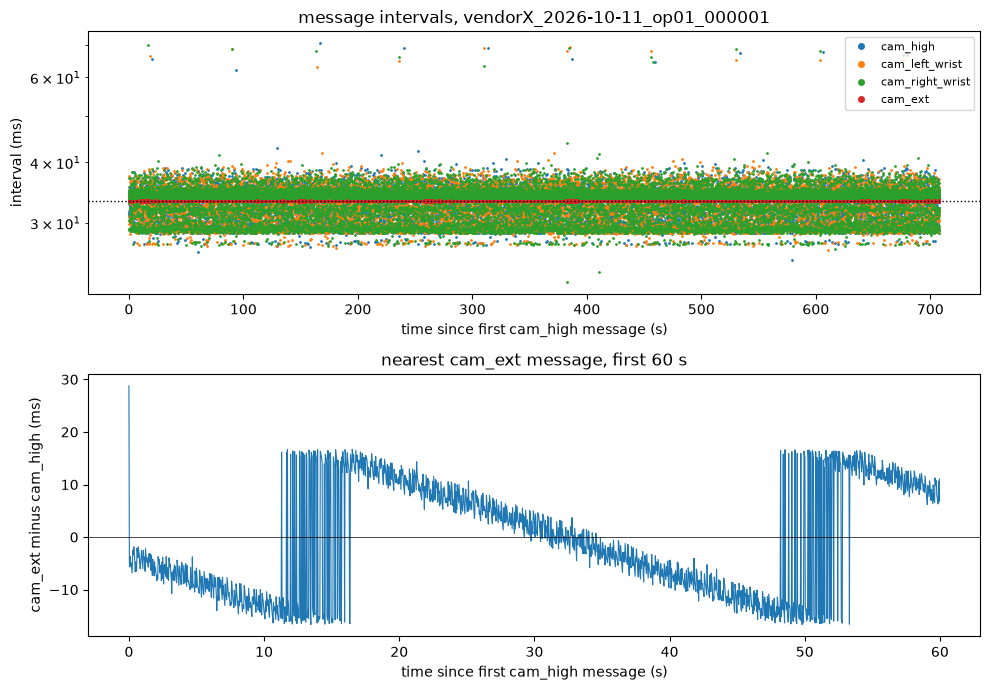

In [13]:
try:
    eid = EP_IDS[0]
    t0 = LT[eid]["cam_high"][0]
    fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 7))
    for cam in CAMS:
        t = LT[eid][cam]
        d = np.diff(t) / 1e6
        d = np.where(d > 0, d, np.nan)
        a1.plot((t[1:] - t0) / 1e9, d, ".", ms=2, label=cam)
    a1.axhline(33.3, ls=":", color="k", lw=1)
    a1.set_yscale("log")
    a1.set_xlabel("time since first cam_high message (s)")
    a1.set_ylabel("interval (ms)")
    a1.set_title(f"message intervals, {eid}")
    a1.legend(markerscale=4, fontsize=8)
    hi, sdiff = NEAR[eid]
    x = (hi - t0) / 1e9
    m = x <= 60
    a2.plot(x[m], sdiff[m], lw=0.8)
    a2.axhline(0, color="k", lw=0.5)
    a2.set_xlabel("time since first cam_high message (s)")
    a2.set_ylabel("cam_ext minus cam_high (ms)")
    a2.set_title("nearest cam_ext message, first 60 s")
    fig.tight_layout()
    fig.savefig(REPORTS / "08d_message_timing.png", dpi=150)
    plt.show()
except Exception as ex:
    problem("figure", ex)

## Hypothesis tests
Checks the expected properties of the files and saves the table.

In [14]:
tests = []


def add(tid, text, fn, info=False):
    try:
        measured, ok = fn()
        res = "INFO" if info else ("PASS" if ok else "FLAG")
    except Exception as ex:
        measured, res = f"not computed ({type(ex).__name__})", ("INFO" if info else "FLAG")
    tests.append({"id": tid, "hypothesis": text, "measured": measured, "result": res})


n_ep = len(EP_IDS)


def g1():
    n = sum(1 for e in EP_IDS if EPCHK[e]["opens"])
    return f"{n} of {n_ep} files open", n == n_ep and n > 0


def g2():
    n = sum(1 for e in EP_IDS if EPCHK[e].get("n_channels") == 4 and EPCHK[e].get("schema_ok"))
    return f"{n} of {n_ep} files with 4 protobuf channels", n == n_ep and n > 0


def g3():
    n = int(CHK["count_ok"].sum())
    return f"{n} of {len(CHK)} channels equal", n == len(CHK) and n > 0


def g4():
    a = sum(1 for e in EP_IDS if EPCHK[e].get("order_global_ok"))
    b = int(CHK["order_channel_ok"].sum())
    return f"file order ok {a} of {n_ep}, per channel ok {b} of {len(CHK)}", a == n_ep and b == len(CHK) and n_ep > 0


def g5():
    n = sum(1 for e in EP_IDS if EPCHK[e].get("meta_found") and EPCHK[e].get("meta_ok"))
    k = {len(REQ[e]) for e in EP_IDS}
    full = FINAL_KEYS_ONLY or k == {17}
    return f"{n} of {n_ep} records ok, required keys {sorted(k)}", n == n_ep and n > 0 and full


def g6():
    n = int((CHK["idr_sps_pps_ok"] & CHK["format_ok"] & CHK["frame_id_ok"]).sum())
    return f"{n} of {len(CHK)} first messages ok", n == len(CHK) and n > 0


def g7():
    n = int(CHK["identical"].sum())
    return f"{n} of {len(CHK)} streams identical", n == len(CHK) and n > 0


def g8():
    s = max(abs(TC[e]["start_diff_ms"]) for e in EP_IDS)
    t = max(abs(TC[e]["stop_diff_ms"]) for e in EP_IDS)
    return f"max start diff {s:.3f} ms, max stop diff {t:.1f} ms", s <= 1 and t <= 40


def g9():
    return (f"equal pairs {int(TC6['equal_pairs'].sum())}, skipped slots {int(TC6['skipped_slots'].sum())}, "
            f"cam_ext intervals under 20 ms {int(TC6['short_20ms'].fillna(0).sum())}"), None


def g10():
    gb = MAN["size_bytes"].sum() / 1e9
    hours = MAN["duration_s"].sum() / 3600
    return f"{gb:.2f} GB in total, {gb / hours:.2f} GB per hour", None


def g11():
    c = R["cli"]
    if not c["found"]:
        return "mcap command line tool not found", None
    return f"doctor ok on {c['doctor_ok']} of {c['doctor_total']} files", None


def g12():
    a = [R["ts"][e]["ext_start_ms"] for e in EP_IDS]
    b = [R["ts"][e]["ext_stop_ms"] for e in EP_IDS]
    ok = all(0 <= x <= 70 for x in a + b)
    return f"start {min(a):.1f} to {max(a):.1f} ms, stop {min(b):.1f} to {max(b):.1f} ms", ok


def g13():
    return f"lag 06 {LAG06:.4f} s, lag 08b {LAG08B:.4f} s, difference {LAG_DIFF:.4f} s", None


add("G1", "every file opens with the reader", g1)
add("G2", "four channels per file, schema foxglove.CompressedVideo, encoding protobuf", g2)
add("G3", "message counts equal the frame counts", g3)
add("G4", "log times non-decreasing in file order and per channel", g4)
add("G5", "metadata record episode_metadata exists with all 17 required keys as strings", g5)
add("G6", "first message of each channel is an IDR frame with SPS and PPS", g6)
add("G7", "reassembled streams are byte-identical to the .h264 files", g7)
add("G8", "capture start within 1 ms and capture stop within 40 ms of the cam_high messages", g8)
add("G9", "equal timestamp pairs, skipped slots and irregular cam_ext intervals", g9, info=True)
add("G10", "total mcap size and GB per hour", g10, info=True)
add("G11", "mcap command line tool and doctor result", g11, info=True)
add("G12", "cam_ext first and last timestamps within 0 to 70 ms of capture start and stop", g12)
add("G13", "lag of notebook 06 agrees with notebook 08b", g13, info=True)

HYP = pd.DataFrame(tests)
HYP.to_csv(REPORTS / "08d_hypothesis_check.csv", index=False)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 100)
print(HYP.to_string(index=False))

 id                                                                       hypothesis                                                         measured result
 G1                                                 every file opens with the reader                                                4 of 4 files open   PASS
 G2       four channels per file, schema foxglove.CompressedVideo, encoding protobuf                            4 of 4 files with 4 protobuf channels   PASS
 G3                                            message counts equal the frame counts                                          16 of 16 channels equal   PASS
 G4                           log times non-decreasing in file order and per channel                    file order ok 4 of 4, per channel ok 16 of 16   PASS
 G5     metadata record episode_metadata exists with all 17 required keys as strings                            4 of 4 records ok, required keys [19]   FLAG
 G6                   first message of each channel is an 

## Summary
Saves the summary json and builds the zip with the 08d reports and the final metadata.

In [15]:
def conv(o):
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return float(o)
    if isinstance(o, np.bool_):
        return bool(o)
    return str(o)


try:
    gb = float(MAN["size_bytes"].sum() / 1e9) if MAN is not None and len(MAN) else None
    hours = float(MAN["duration_s"].sum() / 3600) if MAN is not None and len(MAN) else None
    summary = {
        "notebook": NB_NAME,
        "run_time_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(),
        "run_seconds": round(time.time() - T_START, 1),
        "flags": {"FORCE": FORCE, "FINAL_KEYS_ONLY": FINAL_KEYS_ONLY},
        "versions": VERS,
        "episode_ids": EP_IDS,
        "lag_s": {"notebook_06": LAG06, "notebook_08b": LAG08B, "difference": LAG_DIFF},
        "total_gb": gb,
        "gb_per_hour": (gb / hours) if gb and hours else None,
        "files": MAN.drop(columns=["topics"]).to_dict("records") if MAN is not None and len(MAN) else [],
        "cam_ext_time_checks": R.get("ts", {}),
        "cam_ext_to_cam_high_ms": TC,
        "tests": {r["id"]: {"result": r["result"], "measured": r["measured"]} for r in tests},
    }
    with open(REPORTS / "08d_summary.json", "w", encoding="utf-8") as f:
        json.dump(summary, f, indent=2, default=conv)

    zip_path = REPORTS / "share_08d.zip"
    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
        for p in sorted(REPORTS.glob("08d_*")):
            z.write(p, arcname=p.name)
        for eid, m in META.items():
            z.writestr(f"metadata_final/{eid}.json", json.dumps(m, indent=2, ensure_ascii=False))

    n_pass = sum(1 for r in tests if r["result"] == "PASS")
    n_flag = sum(1 for r in tests if r["result"] == "FLAG")
    print(f"episodes: {len(EP_IDS)}, files written to {OUT.relative_to(ROOT)}")
    if gb:
        print(f"total size: {gb:.2f} GB")
    print(f"tests: {n_pass} pass, {n_flag} flag, {len(tests) - n_pass - n_flag} info")
    print(f"run time: {time.time() - T_START:.0f} s")
    print("zip:", zip_path)
except Exception as ex:
    problem("summary", ex)

episodes: 4, files written to mcap\v1_1
total size: 5.98 GB
tests: 8 pass, 1 flag, 4 info
run time: 72 s
zip: C:\workstation\3RD YEAR\ego_pipeline\reports\share_08d.zip
